# Partie A — Cavité entraînée à $Re = 100$ : solveur de référence vérifié

Plan du notebook (cf. `PLAN.md`, étapes 1 à 3) :

1. **Vérification du solveur de Poisson** (gradient conjugué sans matrice, `cavity/common.py`)
   sur des solutions connues, en Dirichlet (pour $\psi$) et en Neumann (pour $p$).
2. M1 (projection) à $Re = 100$ pour $N = 32, 64, 128$ : profils vs Ghia, justification de la grille,
   $K(t)$, $P(t)$, $P$ stationnaire en fonction de $\ln N$.
3. M2 ($\psi$–$\omega$, Thom) et comparaison M1 / M2 / Ghia.

Adimensionnement : $L = U = \rho = 1$, $\nu = 1/Re$. Grille colocalisée aux nœuds, $h = 1/N$.

In [1]:
# Imports et chemins : le notebook est dans notebooks/, le paquet cavity/ est à la racine du projet
import os
# Contournement d'un défaut de l'environnement CFD sur cette machine : la couche de threads OpenMP
# de MKL fait planter toute algèbre linéaire numpy (np.linalg, donc aussi matplotlib) ; on force
# MKL en séquentiel. Doit être fixé AVANT le premier import de numpy. Sans effet sur nos calculs.
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

from cavity.common import solve_poisson

GRIDS_POISSON = (16, 32, 64)       # grilles demandées pour la vérification du Poisson
TOL_CG = 1e-10                     # résidu relatif : bien sous l'erreur de discrétisation attendue


def observed_slopes(n_list, errors):
    # Pente observée entre deux grilles successives (h divisé par 2) : log2(e_N / e_2N),
    # et pente globale par régression linéaire de log(e) en fonction de log(h) (workshop 9).
    # Régression écrite à la main : pente des moindres carrés = cov(log h, log e) / var(log h).
    e = np.asarray(errors, dtype=float)
    local = np.log2(e[:-1] / e[1:])
    log_h = np.log(1.0 / np.asarray(n_list, dtype=float))
    log_e = np.log(e)
    dh = log_h - log_h.mean()
    global_fit = np.sum(dh * (log_e - log_e.mean())) / np.sum(dh * dh)
    return local, global_fit

## 1. Vérification du solveur de Poisson

### 1.a Dirichlet : $\phi = (x^2-1)(y^2-1)$ (workshop 11.1)

**Ce qu'on fait.** On résout $\Delta\phi = f = 2(x^2 + y^2 - 2)$ sur $[-1, 1]^2$ avec $\phi = 0$ au bord
(problème du workshop 11.1, donc sur $[-1,1]^2$ et non sur le carré unité : c'est là que $\phi$ s'annule au bord ;
le pas vaut $h = 2/N$). Départ du gradient conjugué de zéro, tolérance $10^{-10}$ sur le résidu relatif.

**Ce qu'on attend.** Attention : l'erreur de troncature du laplacien 5 points est
$\tfrac{h^2}{12}(\partial^4_x\phi + \partial^4_y\phi) + O(h^4)$ (cours §2.3), et ici $\phi$ est de degré 2 en
chaque variable : **le schéma est exact**. L'erreur ne mesure donc que l'arrêt du gradient conjugué
($\sim 10^{-12}$) ; il n'y a **pas de pente 2** à observer sur ce cas. Il sert à vérifier que le solveur
(stencil, conditions aux limites, gradient conjugué) est juste. Nombre d'itérations attendu : $O(N)$
(complexité $O(n^{3/2})$ avec $n = N^2$ inconnues, cours §4.8).

In [2]:
rows_dir = []
for n in GRIDS_POISSON:
    h = 2.0 / n
    x = np.linspace(-1.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")          # [i, j] <-> (x, y)
    phi_exact = (X**2 - 1.0) * (Y**2 - 1.0)
    f = 2.0 * (X**2 + Y**2 - 2.0)
    phi, n_iter = solve_poisson(f[1:-1, 1:-1], h, "dirichlet", tol=TOL_CG)
    err = np.abs(phi - phi_exact).max()
    rows_dir.append((n, err, n_iter))
    print(f"N = {n:3d}   max|phi - phi_exact| = {err:.3e}   itérations GC = {n_iter}")

N =  16   max|phi - phi_exact| = 1.594e-12   itérations GC = 28
N =  32   max|phi - phi_exact| = 1.108e-12   itérations GC = 59
N =  64   max|phi - phi_exact| = 9.919e-13   itérations GC = 120


**Lecture.** Erreur $\sim 10^{-12}$ sur les trois grilles, indépendante de $N$ : c'est la précision d'arrêt du
gradient conjugué, comme prévu pour un schéma exact sur ce polynôme. Le nombre d'itérations double
quand $N$ double : $O(N)$, conforme au cours (§4.8).

### 1.b Complément Dirichlet : $\phi = \sin(\pi x)\sin(\pi y)$ sur $[0, 1]^2$

**Ce qu'on fait.** Le cas 1.a ne peut pas donner d'ordre. On ajoute donc un cas dont la dérivée quatrième
n'est pas nulle : $\Delta\phi = -2\pi^2\phi$, $\phi = 0$ sur les parois du carré unité (notre domaine).

**Ce qu'on attend.** Pente $\approx 2$. Remarque : $\sin(\pi x_i)\sin(\pi y_j)$ est un **vecteur propre** du laplacien
discret en Dirichlet, donc le gradient conjugué converge en **1 itération** (le résidu initial est colinéaire à
un vecteur propre) : ce cas ne sert pas à compter les itérations, c'est le cas 1.a qui le fait.

In [3]:
rows_sin = []
for n in GRIDS_POISSON:
    h = 1.0 / n
    x = np.linspace(0.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    phi_exact = np.sin(np.pi * X) * np.sin(np.pi * Y)
    phi, n_iter = solve_poisson((-2.0 * np.pi**2 * phi_exact)[1:-1, 1:-1], h, "dirichlet", tol=TOL_CG)
    err = np.abs(phi - phi_exact).max()
    rows_sin.append((n, err, n_iter))
    print(f"N = {n:3d}   max|phi - phi_exact| = {err:.3e}   itérations GC = {n_iter}")

local, glob = observed_slopes(GRIDS_POISSON, [r[1] for r in rows_sin])
print("pentes locales :", np.round(local, 3), "  pente globale :", round(glob, 3))

N =  16   max|phi - phi_exact| = 3.219e-03   itérations GC = 1
N =  32   max|phi - phi_exact| = 8.036e-04   itérations GC = 1
N =  64   max|phi - phi_exact| = 2.008e-04   itérations GC = 1
pentes locales : [2.002 2.001]   pente globale : 2.001


### 1.c Neumann : $\phi = \cos(\pi x)\cos(\pi y)$ sur $[0, 1]^2$

**Ce qu'on fait.** $\Delta\phi = -2\pi^2\phi$ avec $\partial\phi/\partial n = 0$ sur les quatre parois (vrai pour
cette $\phi$), exactement comme pour la pression de M1 : bord = voisin intérieur (Neumann décentrée
d'ordre 1, cours §4.2.2.2), moyenne du second membre retirée, $\phi$ à moyenne nulle à chaque itération.
La moyenne de $\phi_\text{exact}$ sur les nœuds intérieurs est nulle (symétrie), on peut donc comparer directement.
Erreur mesurée sur les nœuds intérieurs (les nœuds de bord sont une simple recopie).

**Ce qu'on attend.** On pourrait attendre une pente $\approx 2$ (ordre du laplacien), mais l'analyse avant calcul prévoit plutôt
**une pente $\approx 1$** : la règle $\phi_0 = \phi_1$ impose $\partial\phi/\partial n = 0$ **entre** les nœuds 0 et 1,
c'est-à-dire que le schéma résout (à l'ordre 2) le problème de Neumann sur le domaine décalé
$[h/2,\ 1-h/2]^2$. En 1D, la solution de $\phi'' = -\pi^2\cos(\pi x)$ avec $\phi'(h/2) = \phi'(1-h/2) = 0$ vaut
$\cos(\pi x) + \pi\sin(\pi h/2)\,x + c$ : l'écart à la vraie solution est une **pente linéaire en $x$**,
d'amplitude $\approx \tfrac{\pi^2}{2}h\,(x - \tfrac12)$, donc une erreur maximale $\approx \tfrac{\pi^2}{4}h \approx 2.5\,h$ en 1D.

**Version retenue pour M1 : nœuds fantômes** (`bc="neumann_ghost"`, `docs/adr/0002` §6). Les nœuds de paroi deviennent des
inconnues ; le voisin manquant est un fantôme miroir pair $\phi_{-1} = \phi_1$ ($\partial\phi/\partial n = 0$ par la dérivée **centrée** d'ordre 2) ;
les lignes de paroi sont pondérées par les poids des trapèzes (½ paroi, ¼ coin) pour garder la symétrie exigée par le
gradient conjugué ; compatibilité et moyenne nulle deviennent des moyennes pondérées ($\iint \phi\,dS = 0$).
Erreur mesurée sur **tous** les nœuds. On attend une pente $\approx 2$.

In [4]:
rows_neu = []
profiles_neu = {}                     # erreur le long de y = 0.5 (pour la figure)
for n in GRIDS_POISSON:
    h = 1.0 / n
    x = np.linspace(0.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    phi_exact = np.cos(np.pi * X) * np.cos(np.pi * Y)
    phi, n_iter = solve_poisson((-2.0 * np.pi**2 * phi_exact)[1:-1, 1:-1], h, "neumann", tol=TOL_CG)
    error = phi - phi_exact
    err = np.abs(error[1:-1, 1:-1]).max()
    rows_neu.append((n, err, n_iter))
    profiles_neu[n] = (x, error[:, n // 4])          # coupe y = 0.25 (cos(pi y) = 0 en y = 0.5)
    print(f"N = {n:3d}   max|phi - phi_exact| (intérieur) = {err:.3e}   err/h = {err / h:.2f}"
          f"   itérations GC = {n_iter}   moyenne(phi) = {phi[1:-1, 1:-1].mean():+.1e}")

local, glob = observed_slopes(GRIDS_POISSON, [r[1] for r in rows_neu])
print("pentes locales :", np.round(local, 3), "  pente globale :", round(glob, 3))

# Version retenue pour M1 : nœuds fantômes (second membre et erreur sur TOUS les nœuds)
rows_ghost = []
for n in GRIDS_POISSON:
    h = 1.0 / n
    x = np.linspace(0.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    phi_exact = np.cos(np.pi * X) * np.cos(np.pi * Y)       # moyenne des trapèzes nulle (symétrie)
    phi, n_iter = solve_poisson(-2.0 * np.pi**2 * phi_exact, h, "neumann_ghost", tol=TOL_CG)
    err = np.abs(phi - phi_exact).max()
    rows_ghost.append((n, err, n_iter))
    print(f"fantômes  N = {n:3d}   max|phi - phi_exact| (tous nœuds) = {err:.3e}   err/h² = {err * n**2:.3f}"
          f"   itérations GC = {n_iter}")
local, glob = observed_slopes(GRIDS_POISSON, [r[1] for r in rows_ghost])
print("fantômes : pentes locales :", np.round(local, 3), "  pente globale :", round(glob, 3))

N =  16   max|phi - phi_exact| (intérieur) = 1.423e-01   err/h = 2.28   itérations GC = 23   moyenne(phi) = -9.9e-19
N =  32   max|phi - phi_exact| (intérieur) = 8.055e-02   err/h = 2.58   itérations GC = 48   moyenne(phi) = +2.8e-18
N =  64   max|phi - phi_exact| (intérieur) = 4.265e-02   err/h = 2.73   itérations GC = 93   moyenne(phi) = -3.6e-18
pentes locales : [0.821 0.918]   pente globale : 0.869
fantômes  N =  16   max|phi - phi_exact| (tous nœuds) = 3.219e-03   err/h² = 0.824   itérations GC = 33
fantômes  N =  32   max|phi - phi_exact| (tous nœuds) = 8.036e-04   err/h² = 0.823   itérations GC = 68
fantômes  N =  64   max|phi - phi_exact| (tous nœuds) = 2.008e-04   err/h² = 0.823   itérations GC = 134
fantômes : pentes locales : [2.002 2.001]   pente globale : 2.001


**Figure** : erreur max en fonction de $h$ (log-log) pour Dirichlet ($\sin\sin$) et Neumann ($\cos\cos$), avec
les droites de pente 1 et 2 ; à droite, l'erreur Neumann le long de la coupe $y = 1/4$ divisée par $h$
(si l'analyse du domaine décalé est juste, les courbes se superposent : erreur $\propto h$, de forme régulière).

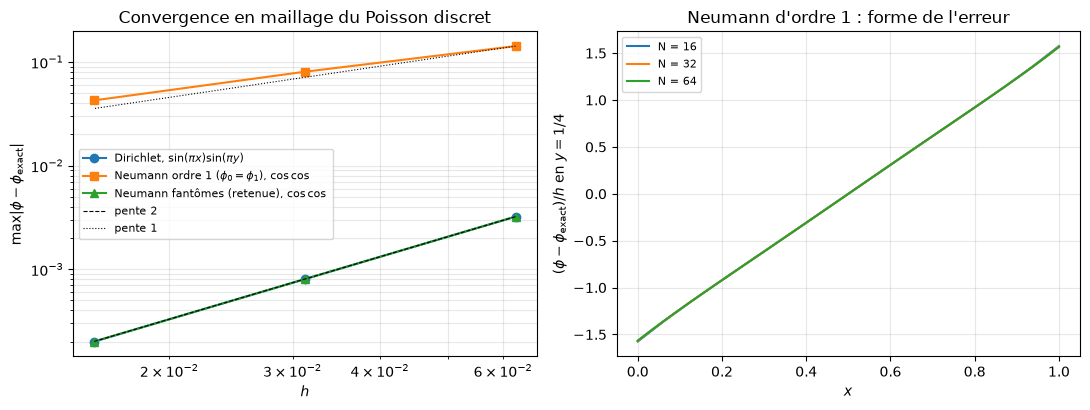

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
h_list = 1.0 / np.array(GRIDS_POISSON, dtype=float)
e_sin = np.array([r[1] for r in rows_sin])
e_neu = np.array([r[1] for r in rows_neu])
e_ghost = np.array([r[1] for r in rows_ghost])
ax.loglog(h_list, e_sin, "o-", label=r"Dirichlet, $\sin(\pi x)\sin(\pi y)$")
ax.loglog(h_list, e_neu, "s-", label=r"Neumann ordre 1 ($\phi_0 = \phi_1$), $\cos\cos$")
ax.loglog(h_list, e_ghost, "^-", label=r"Neumann fantômes (retenue), $\cos\cos$")
ax.loglog(h_list, e_sin[0] * (h_list / h_list[0])**2, "k--", lw=0.8, label="pente 2")
ax.loglog(h_list, e_neu[0] * (h_list / h_list[0])**1, "k:", lw=0.8, label="pente 1")
ax.set_xlabel("$h$")
ax.set_ylabel(r"$\max|\phi - \phi_\mathrm{exact}|$")
ax.set_title("Convergence en maillage du Poisson discret")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)

ax = axes[1]
for n, (x, err_line) in profiles_neu.items():
    ax.plot(x, err_line * n, label=f"N = {n}")     # erreur / h
ax.set_xlabel("$x$")
ax.set_ylabel(r"$(\phi - \phi_\mathrm{exact}) / h$ en $y = 1/4$")
ax.set_title("Neumann d'ordre 1 : forme de l'erreur")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(FIG / "A_poisson_convergence.png", dpi=150)
plt.show()

# Résultats numériques
table = np.array([[n, ed, it_d, es, it_s, en, it_n, eg, it_g]
                  for (n, ed, it_d), (_, es, it_s), (_, en, it_n), (_, eg, it_g)
                  in zip(rows_dir, rows_sin, rows_neu, rows_ghost)])
np.savetxt(RES / "A_poisson_verification.csv", table, delimiter=",", fmt="%.6e",
           header="N,err_dirichlet_quadratique,iter_dirichlet_quadratique,err_dirichlet_sinsin,"
                  "iter_dirichlet_sinsin,err_neumann_ordre1_coscos,iter_neumann_ordre1_coscos,"
                  "err_neumann_fantomes_coscos,iter_neumann_fantomes_coscos")

**Interprétation.**

- **Dirichlet** : pente 2 sur $\sin\sin$, l'ordre attendu du laplacien 5 points ; avec le cas exact 1.a, le
  solveur Dirichlet (utilisé pour $\psi$ dans M2) est vérifié.
- **Neumann** : pente $\approx 1$ (0,82 puis 0,92, globale 0,87 : elle tend vers 1 quand $h$ diminue), et non 2.
  Ce n'est pas un défaut du gradient conjugué : la règle $\phi_0 = \phi_1$ (Neumann décentrée d'ordre 1,
  cours §4.2.2.2) revient à placer la paroi en $h/2$. Les courbes « erreur / $h$ » des trois grilles se
  superposent, ce qui confirme une erreur **globale** en $O(h)$, régulière et étalée sur tout le domaine
  (pas seulement la rangée de bord). Erreur max mesurée $\approx 2.3\,h$ à $2.7\,h$ ; l'estimation 1D donne
  $\approx 2.5\,h$, du même ordre (en 2D la correction n'est pas exactement la pente linéaire du cas 1D,
  on ne prétend donc qu'à l'ordre de grandeur).
- **Neumann à nœuds fantômes** : pente **2.00**, erreur $\approx 0.82\,h^2$, environ 200 fois plus petite que l'ordre 1 à $N = 64$,
  pour ~40 % d'itérations en plus. C'est la version retenue pour la pression de M1 : la comparaison M1 / M2 de la
  section 3, faite d'abord avec l'ordre 1, désignait la Neumann d'ordre 1 comme suspecte (`docs/adr/0002` §5).
- **Itérations** : $O(N)$ pour toutes les conditions aux limites (départ de zéro). En marche en temps, le départ
  à chaud depuis la pression du pas précédent en réduit le nombre.

## 2. M1 (projection) à $Re = 100$ : validation et justification de la grille

### 2.a Calculs

**Ce qu'on fait.** M1 (`cavity/projection.py`, cours §7.3.2 et workshop 15) : Euler explicite, advection
**centrée**, diffusion centrée, pression par gradient conjugué avec **Neumann d'ordre 2 par nœuds fantômes** (§1.c,
`docs/adr/0002` §6 : second membre $\nabla\cdot u^*/\Delta t$ à tous les nœuds, divergence décentrée d'ordre 2 aux parois ;
tol $= 10^{-8}$, départ à chaud). Départ du repos, couvercle $U_t = 1 - e^{-t}$. $\Delta t$ = limites de stabilité du cours (§5.3), marge 0.8.
(La première version de M1, Neumann d'ordre 1, est gardée sous le nom « M1 ordre 1 » pour la comparaison de la section 3.)

**Critère d'arrêt** (`docs/adr/0003-pas-de-temps-et-arrets.md` §2), comme au Projet 1 (question b) : on surveille le
**résidu stationnaire** $R = (u^{n+1}-u^n)/\Delta t$ (composantes $u$ et $v$, nœuds intérieurs, norme L2). Avec Euler
explicite, $R$ est exactement le membre de droite discret ($-$advection $+\ \nu\Delta u - \nabla p$) : il mesure de combien le
champ viole les équations stationnaires, et ne dépend pas de $\Delta t$. Le fluide partant du repos, le résidu initial est
nul : la référence est prise à $t_\text{ref} = 10$ (rampe du couvercle terminée), et on s'arrête dès que
$\|R\| < \varepsilon\,\|R(t_\text{ref})\|$. La valeur de $\varepsilon$ est fixée par le test de 2.b.

Cas calculés (tous indépendants, donc lancés **en parallèle**, un processus par cas ; noyaux compilés par **Numba**) :
$N = 32, 64, 128$ pour $\varepsilon = 10^{-2}, 10^{-3}, 10^{-4}$. Résultats sauvegardés dans `results/` et relus si présents
(`RECOMPUTE = True` pour tout recalculer).

**Ce qu'on attend.**
- $\Delta t$ limité par l'advection (CFL) à $N = 32$ et par la diffusion (Fourier) à $N = 64, 128$ (croisement à $N = Re/2 = 50$).
- Le résidu décroît en $e^{-\lambda t}$ près du stationnaire : chaque décade de $\varepsilon$ ajoute la même durée $\ln 10/\lambda$.

In [6]:
from cavity.projection import run_projection

RE = 100
NU = 1.0 / RE
GRIDS = (32, 64, 128)
CG_TOL = 1e-8
T_REF = 10.0
EPS_CANDIDATES = (1e-2, 1e-3, 1e-4)
RECOMPUTE = False


def save_run(run, path):
    np.savez(path, **{key: np.asarray(val) for key, val in run.items()})


def load_run(path):
    data = np.load(path)
    return {key: (data[key].item() if data[key].ndim == 0 else data[key]) for key in data.files}


from functools import partial

from cavity.psi_omega import run_psi_omega

# Méthodes (même signature) : M1 = projection avec Neumann à fantômes (retenue) ; M1neu1 = première
# version de M1 (Neumann d'ordre 1), gardée pour la comparaison ; M2 = ψ–ω.
RUNNERS = {"M1": run_projection, "M1neu1": partial(run_projection, pressure_bc="neumann"),
           "M2": run_psi_omega}


def run_path(n, cg_tol, eps, method="M1", dt=None):
    tag = "" if dt is None else f"_dt{dt:.4e}"      # Δt imposé (études de la section 2.e)
    return RES / f"A_{method}_N{n}_tol{cg_tol:.0e}_res{eps:.0e}{tag}.npz"


def compute_missing(cases, method="M1"):
    # cases : tuples (N, tol GC, ε) ou (N, tol GC, ε, Δt imposé).
    # Les calculs sont indépendants : on lance ceux qui manquent EN PARALLÈLE, un processus par cas
    # (chaque calcul n'utilise qu'un cœur ; la machine en a 32). Le temps total devient celui du cas
    # le plus long au lieu de la somme. Aucune modification du schéma numérique.
    from concurrent.futures import ProcessPoolExecutor
    missing = [c for c in cases if RECOMPUTE or not run_path(*c[:3], method=method, dt=c[3] if len(c) > 3 else None).exists()]
    if not missing:
        return
    os.environ["PYTHONPATH"] = str(ROOT)      # les processus fils doivent trouver le paquet cavity/
    with ProcessPoolExecutor(max_workers=len(missing)) as pool:
        futures = {}
        for c in missing:
            kwargs = dict(cg_tol=c[1], residual_tol=c[2], t_ref=T_REF)
            if len(c) > 3:
                kwargs["dt"] = c[3]
            futures[c] = pool.submit(RUNNERS[method], c[0], RE, "centered", **kwargs)
        for case, future in futures.items():
            dt_case = case[3] if len(case) > 3 else None
            save_run(future.result(), run_path(*case[:3], method=method, dt=dt_case))
            extra = "" if dt_case is None else f", Δt imposé = {dt_case:.3e}"
            print(f"calculé : {method}, N = {case[0]}, tol GC = {case[1]:.0e}, ε = {case[2]:.0e}{extra}")


def get_run(n, eps, cg_tol=CG_TOL, method="M1", dt=None):
    # Relit un calcul sauvegardé dans results/ (compute_missing l'a produit si besoin).
    return load_run(run_path(n, cg_tol, eps, method=method, dt=dt))


def active_limit(h, nu):
    # Quelle limite de stabilité fixe Δt (cf. cavity/common.time_step)
    limits = {"Fourier": h**2 / (4 * nu), "CFL": h / 2, "centré 2ν": 2 * nu}
    return min(limits, key=limits.get)


compute_missing([(n, CG_TOL, eps) for n in GRIDS for eps in EPS_CANDIDATES])

print(f"{'N':>4} {'dt':>9} {'limite':>9} | {'ε':>6} {'pas':>6} {'t_final':>7} {'calcul (s)':>10} "
      f"{'it. GC':>6} {'||R(t_ref)||':>12} {'arrêt':>8}")
for n in GRIDS:
    for eps in EPS_CANDIDATES:
        r = get_run(n, eps)
        stop = "critère" if r["converged"] else "t_max !"      # t_max atteint = signal d'alerte
        print(f"{n:4d} {r['dt']:9.3e} {active_limit(r['h'], NU):>9} | {eps:6.0e} {r['n_steps']:6d} "
              f"{r['t_final']:7.2f} {r['wall_time']:10.1f} {r['cg_iterations'].mean():6.1f} "
              f"{r['residual_ref']:12.3e} {stop:>8}")
print("Temps mesurés avec 9 calculs en parallèle (cœurs partagés : temps un peu pessimistes).")

calculé : M1, N = 32, tol GC = 1e-08, ε = 1e-02
calculé : M1, N = 32, tol GC = 1e-08, ε = 1e-03
calculé : M1, N = 32, tol GC = 1e-08, ε = 1e-04
calculé : M1, N = 64, tol GC = 1e-08, ε = 1e-02
calculé : M1, N = 64, tol GC = 1e-08, ε = 1e-03
calculé : M1, N = 64, tol GC = 1e-08, ε = 1e-04
calculé : M1, N = 128, tol GC = 1e-08, ε = 1e-02
calculé : M1, N = 128, tol GC = 1e-08, ε = 1e-03
calculé : M1, N = 128, tol GC = 1e-08, ε = 1e-04
   N        dt    limite |      ε    pas t_final calcul (s) it. GC ||R(t_ref)||    arrêt
  32 1.250e-02       CFL |  1e-02   1476   18.45        5.2   80.1    3.072e-02  critère
  32 1.250e-02       CFL |  1e-03   1811   22.64        5.4   67.6    3.072e-02  critère
  32 1.250e-02       CFL |  1e-04   2150   26.87        5.8   57.5    3.072e-02  critère
  64 4.883e-03   Fourier |  1e-02   3787   18.49       21.4  127.7    6.155e-02  critère
  64 4.883e-03   Fourier |  1e-03   4652   22.71       22.2  105.9    6.155e-02  critère
  64 4.883e-03   Fourier |  1e-

**Lecture.**
- $\Delta t$ : CFL à $N = 32$, Fourier à $N = 64$ et $128$, comme prévu (croisement à $N = 50$).
- Tous les calculs s'arrêtent par le critère (aucun n'atteint $t_\max$) : l'écoulement devient bien stationnaire.
- **Pour un même $\varepsilon$, les trois grilles s'arrêtent au même instant** ($t \approx 18.5$ pour $\varepsilon = 10^{-2}$), alors que leurs $\Delta t$
  diffèrent d'un facteur 10 : le critère sur le résidu ne dépend pas de $\Delta t$, ce qui était son but.
- Chaque décade de $\varepsilon$ ajoute $\approx 4.2$ unités de temps, soit $\ln 10/\lambda$ avec $\lambda \approx 0.54$ (cf. 2.f).
- Coût ($\varepsilon = 10^{-2}$, $N = 32 \to 64 \to 128$) : ~1 s, ~8 s, ~2 min. La Neumann à fantômes coûte un peu plus d'itérations
  du gradient conjugué par pas que l'ordre 1 (§1.c).

### 2.b Choix de $\varepsilon$ (validation du critère d'arrêt, ADR 0003 §2)

**Ce qu'on fait.** Pour chaque $\varepsilon$, on compare les profils sur les lignes médianes à ceux obtenus avec $\varepsilon/10$, sur la
grille la plus fine ($N = 128$, où l'écart à Ghia est le plus petit, donc l'exigence la plus forte). Règle de l'ADR :
l'erreur d'arrêt doit être **très petite** devant l'écart à Ghia ; on la chiffre ici à **au plus 10 %** de l'écart à Ghia,
et on retient le plus grand $\varepsilon$ qui la respecte (le moins coûteux).
(Le cas vraiment le plus défavorable est $Re = 5000$, où l'amortissement est le plus lent : test à refaire en Partie B.)

**Ce qu'on attend.** L'écart entre $\varepsilon$ et $\varepsilon/10$ décroît d'un facteur ~10 par décade (décroissance exponentielle).

In [7]:
ghia_u = np.loadtxt(ROOT / "ref_data" / "ghia1982_u_vertical_centerline.csv", delimiter=",")
ghia_v = np.loadtxt(ROOT / "ref_data" / "ghia1982_v_horizontal_centerline.csv", delimiter=",")
y_ghia = np.round(ghia_u[:, 0] * 128) / 128          # positions exactes sur la grille 129 de Ghia
x_ghia = np.round(ghia_v[:, 0] * 128) / 128
u_ghia = ghia_u[:, 1]                                 # colonne Re = 100
v_ghia = ghia_v[:, 1]
STOP_FRACTION = 0.10                                  # « très petit » = au plus 10 % de l'écart à Ghia


def centerlines(run):
    # u(0.5, y) : colonne i = N/2 ; v(x, 0.5) : ligne j = N/2
    n = run["N"]
    return run["u"][n // 2, :], run["v"][:, n // 2]


def ghia_errors(run):
    # Écart max à Ghia sur ses points intérieurs (les points de paroi sont imposés, donc exacts)
    u_c, v_c = centerlines(run)
    in_u = (y_ghia > 0) & (y_ghia < 1)
    in_v = (x_ghia > 0) & (x_ghia < 1)
    err_u = np.abs(np.interp(y_ghia[in_u], run["y"], u_c) - u_ghia[in_u]).max()
    err_v = np.abs(np.interp(x_ghia[in_v], run["x"], v_c) - v_ghia[in_v]).max()
    return err_u, err_v


EPS = None
for eps, eps_tight in zip(EPS_CANDIDATES[:-1], EPS_CANDIDATES[1:]):
    r_a, r_b = get_run(128, eps), get_run(128, eps_tight)
    ua, va = centerlines(r_a)
    ub, vb = centerlines(r_b)
    eu, ev = ghia_errors(r_b)
    frac_u = np.abs(ua - ub).max() / eu
    frac_v = np.abs(va - vb).max() / ev
    ok = max(frac_u, frac_v) <= STOP_FRACTION
    print(f"ε = {eps:.0e} vs {eps_tight:.0e} : max|Δu| = {np.abs(ua - ub).max():.2e} ({frac_u:.1%} de l'écart à Ghia), "
          f"max|Δv| = {np.abs(va - vb).max():.2e} ({frac_v:.1%})  -> {'suffit' if ok else 'insuffisant'}")
    if ok and EPS is None:
        EPS = eps
if EPS is None:
    raise RuntimeError("aucun ε candidat ne respecte la règle : élargir EPS_CANDIDATES")
print(f"\nε retenu : {EPS:.0e}")
for eps in EPS_CANDIDATES:
    r = get_run(128, eps)
    print(f"   ε = {eps:.0e} : arrêt à t = {r['t_final']:6.2f}   K = {r['K'][-1]:.6f}   P = {r['P'][-1]:.6f}")

ε = 1e-02 vs 1e-03 : max|Δu| = 2.47e-05 (0.4% de l'écart à Ghia), max|Δv| = 2.61e-05 (0.2%)  -> suffit
ε = 1e-03 vs 1e-04 : max|Δu| = 2.46e-06 (0.0% de l'écart à Ghia), max|Δv| = 2.61e-06 (0.0%)  -> suffit

ε retenu : 1e-02
   ε = 1e-02 : arrêt à t =  18.52   K = 0.034941   P = 0.212199
   ε = 1e-03 : arrêt à t =  22.77   K = 0.034943   P = 0.212199
   ε = 1e-04 : arrêt à t =  27.07   K = 0.034943   P = 0.212199


**Lecture.** Passer de $\varepsilon = 10^{-2}$ à $10^{-3}$ ne change les profils que de $2.5\cdot10^{-5}$, soit **0.4 %** de l'écart à Ghia en $u$ (0.2 % en $v$) :
**$\varepsilon = 10^{-2}$ suffit** à $Re = 100$, avec une large marge (règle : 10 %). L'écart est divisé par 10 à chaque décade, comme attendu
pour une décroissance exponentielle ; $K$ et $P$ ne bougent plus au 5ᵉ chiffre. À revérifier à $Re = 5000$ (Partie B, ADR 0003).

### 2.c Profils sur les lignes médianes, comparés à Ghia et al. (1982)

À partir d'ici, tous les calculs sont ceux arrêtés avec le $\varepsilon$ retenu en 2.b.

**Ce qu'on fait.** $u(0.5, y)$ et $v(x, 0.5)$ pour les trois grilles ($x = 0.5$ et $y = 0.5$ sont des nœuds pour $N$ pair),
avec les points de Ghia (`ref_data/`, Tables I et II, colonne $Re = 100$, grille 129×129).
Les abscisses de Ghia sont des multiples de $1/128$ arrondis à 4 décimales : on les remet à leur valeur exacte
$\mathrm{round}(128\,y)/128$. Pour comparer, notre profil est interpolé linéairement aux points de Ghia
(exact pour $N = 128$ ; pour $N = 32, 64$, interpolation d'ordre 2, du même ordre que le schéma).

**Ce qu'on attend.** Les courbes se rapprochent de Ghia quand $N$ augmente ; à $Re = 100$, le tourbillon est
presque centré. Dans la table de Ghia, le minimum de $u$ vaut $-0.21090$ en $y = 0.4531$.

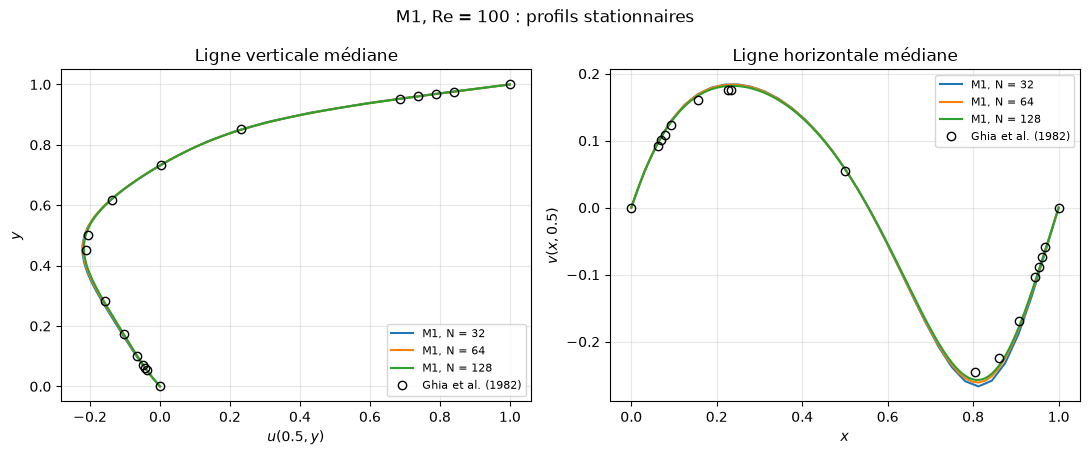

N =  32   max|u - u_Ghia| = 0.0102   max|v - v_Ghia| = 0.0206   min u(0.5, y) = -0.22129 en y = 0.4688   min v(x, 0.5) = -0.26677
N =  64   max|u - u_Ghia| = 0.0090   max|v - v_Ghia| = 0.0158   min u(0.5, y) = -0.21991 en y = 0.4531   min v(x, 0.5) = -0.26100
N = 128   max|u - u_Ghia| = 0.0064   max|v - v_Ghia| = 0.0122   min u(0.5, y) = -0.21721 en y = 0.4609   min v(x, 0.5) = -0.25717


In [8]:
runs = {n: get_run(n, EPS) for n in GRIDS}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for n, r in runs.items():
    u_c, v_c = centerlines(r)
    axes[0].plot(u_c, r["y"], label=f"M1, N = {n}")
    axes[1].plot(r["x"], v_c, label=f"M1, N = {n}")
axes[0].plot(u_ghia, y_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[1].plot(x_ghia, v_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[0].set_xlabel("$u(0.5, y)$"); axes[0].set_ylabel("$y$")
axes[1].set_xlabel("$x$"); axes[1].set_ylabel("$v(x, 0.5)$")
axes[0].set_title("Ligne verticale médiane"); axes[1].set_title("Ligne horizontale médiane")
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"M1, Re = {RE} : profils stationnaires")
fig.tight_layout()
fig.savefig(FIG / "A_M1_profiles.png", dpi=150)
plt.show()

for n, r in runs.items():
    eu, ev = ghia_errors(r)
    u_c, v_c = centerlines(r)
    print(f"N = {n:3d}   max|u - u_Ghia| = {eu:.4f}   max|v - v_Ghia| = {ev:.4f}   "
          f"min u(0.5, y) = {u_c.min():.5f} en y = {r['y'][np.argmin(u_c)]:.4f}   min v(x, 0.5) = {v_c.min():.5f}")

**Lecture.** Les trois grilles sont proches de Ghia dès $N = 32$ (écart max 0.010 en $u$, 0.021 en $v$, contre 0.042 et 0.057 pour la
première version de M1, Neumann d'ordre 1 : section 3). Mais l'écart diminue peu avec $N$ (0.0102 → 0.0090 → 0.0064 en $u$ ;
0.021 → 0.016 → 0.012 en $v$) : M1 creuse **plus** les extrema que Ghia (minimum de $v$ : $-0.267$, $-0.261$, $-0.257$, contre
$-0.245$ chez Ghia ; minimum de $u$ : $-0.217$ à $N = 128$ contre $-0.211$) et s'en rapproche lentement. La section 2.e explique
pourquoi (erreur de projection en $\Delta t$), et la section 3 montre que M1 converge vers la même solution que M2.

### 2.d Justification de la grille : deux courbes de convergence

**Ce qu'on fait** (PLAN.md, étape 2) :
1. écart max à Ghia en fonction de $h$ (log-log) ;
2. écart entre grilles successives $\max|u_N - u_{2N}|$ (et de même pour $v$), sur les nœuds communs des lignes
   médianes : il ne dépend d'aucune référence, sa pente donne **notre** ordre observé.

**Ce qu'on attend.** Schéma d'ordre 2 en espace ⇒ pente $\approx 2$. Trois raisons possibles d'une pente plus faible :
la Neumann d'ordre 1 sur $p$ (cf. ADR 0002, à trancher avec M2 à l'étape 3), les singularités des coins du
couvercle (touchent M1 et M2), et pour la courbe 1, l'erreur propre de Ghia (palier possible).
Avec 3 grilles, la courbe 1 donne 2 pentes locales et la courbe 2 une seule.

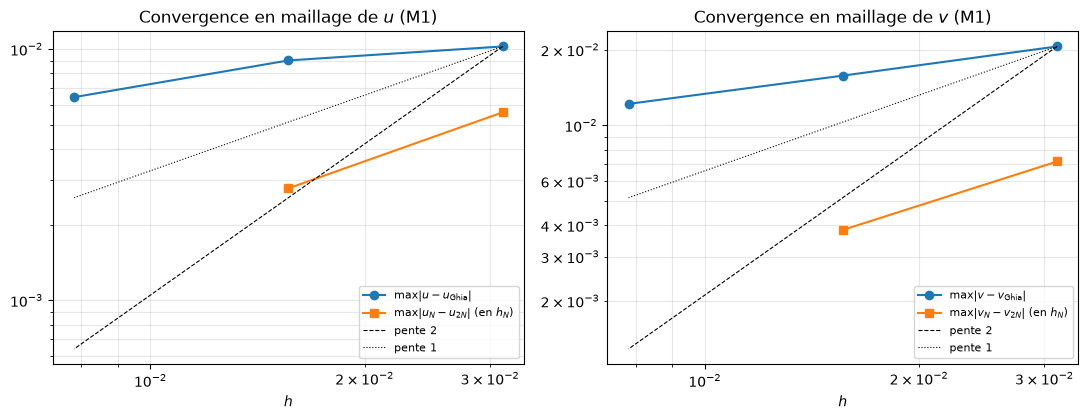

u : écart à Ghia = [0.01024 0.00901 0.00643]  pentes locales [0.18 0.49]  (globale 0.34)
    écart grilles successives = [0.0056  0.00279]  pente 1.00
v : écart à Ghia = [0.02059 0.01575 0.01216]  pentes locales [0.39 0.37]  (globale 0.38)
    écart grilles successives = [0.00717 0.00383]  pente 0.91


In [9]:
h_list = np.array([runs[n]["h"] for n in GRIDS])
err_ghia = np.array([ghia_errors(runs[n]) for n in GRIDS])        # colonnes : u, v

# Écart entre grilles successives sur les nœuds communs (un nœud sur deux de la grille fine)
diff_succ = []
for n in GRIDS[:-1]:
    u_c, v_c = centerlines(runs[n])
    u_f, v_f = centerlines(runs[2 * n])
    diff_succ.append((np.abs(u_c - u_f[::2]).max(), np.abs(v_c - v_f[::2]).max()))
diff_succ = np.array(diff_succ)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for k, name in enumerate(("u", "v")):
    ax = axes[k]
    ax.loglog(h_list, err_ghia[:, k], "o-", label=rf"$\max|{name} - {name}_\mathrm{{Ghia}}|$")
    ax.loglog(h_list[:-1], diff_succ[:, k], "s-", label=rf"$\max|{name}_N - {name}_{{2N}}|$ (en $h_N$)")
    ref = err_ghia[0, k]
    ax.loglog(h_list, ref * (h_list / h_list[0])**2, "k--", lw=0.8, label="pente 2")
    ax.loglog(h_list, ref * (h_list / h_list[0])**1, "k:", lw=0.8, label="pente 1")
    ax.set_xlabel("$h$"); ax.set_title(f"Convergence en maillage de ${name}$ (M1)")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A_M1_grid_convergence.png", dpi=150)
plt.show()

for k, name in enumerate(("u", "v")):
    local, glob = observed_slopes(GRIDS, err_ghia[:, k])
    succ_slope = np.log2(diff_succ[0, k] / diff_succ[1, k])
    print(f"{name} : écart à Ghia = {np.round(err_ghia[:, k], 5)}  pentes locales {np.round(local, 2)}"
          f"  (globale {glob:.2f})")
    print(f"    écart grilles successives = {np.round(diff_succ[:, k], 5)}  pente {succ_slope:.2f}")

**Lecture.**
- **Écart entre grilles successives** (indépendant de Ghia), avec le $\Delta t$ de stabilité : pente **≈ 1.0** ($u$) et 0.9 ($v$), alors que la
  Neumann à fantômes est d'ordre 2 (§1.c). Les écarts sont pourtant petits (0.0056 puis 0.0028 en $u$).
- **Écart à Ghia** : pentes de 0.2 à 0.5, presque un palier, d'autant que Ghia a sa propre erreur (palier visible pour M2, section 3).
- Ces deux courbes ne permettent pas de lire l'ordre de M1 : avec le $\Delta t$ de stabilité, $\Delta t$ change avec $N$, et l'état stationnaire
  de M1 dépend de $\Delta t$. La section 2.e sépare les deux effets.

### 2.e Séparer l'erreur d'espace et l'erreur de projection en $\Delta t$

**Pourquoi.** Au stationnaire, la projection du cours (§7.3.2, pression absente de la prédiction) vérifie exactement
(`docs/adr/0002` §7.3) :
$$D(u) = \Delta t\,(\Delta_h - D\tilde G)\,p ,$$
où $\Delta_h$ est le laplacien que résout le gradient conjugué et $D\tilde G$ celui qu'applique la correction (gradient centré, non
appliqué aux parois). Ces deux laplaciens ne coïncident pas sur grille colocalisée : l'état stationnaire de M1 garde une
divergence $\propto \Delta t$ et **dépend de $\Delta t$** (le facteur $(\Delta_h - D\tilde G)p$ dépend lui-même un peu de $\Delta t$, donc la
dépendance n'est pas forcément linéaire). Son erreur s'écrit donc
$$\text{erreur M1} \approx E_\text{espace}(h) + E_{\Delta t}(\Delta t), \qquad E_{\Delta t} \to 0 \text{ quand } \Delta t \to 0 .$$
Or le $\Delta t$ de stabilité change avec $N$ (CFL à $N = 32$, Fourier ensuite : divisé par 2.56 puis par 4) : l'étude de grille de 2.d
mélange les deux erreurs. M2 n'a pas d'étape de projection : son stationnaire ne dépend pas de $\Delta t$.

**Ce qu'on fait.**
1. **Convergence en $\Delta t$** à $N = 64$ : $\Delta t_0$ (stabilité), $\Delta t_0/2$, $\Delta t_0/4$ pour M1 ; $\Delta t_0/2$ pour M2 (témoin).
2. **Étude de grille à $\Delta t$ fixe** : $N = 32, 64, 128$ avec le même $\Delta t$ (celui de $N = 128$) : la part $E_{\Delta t}$ est (à peu près) la
   même sur toutes les grilles et disparaît des écarts entre grilles, qui ne mesurent plus que l'ordre en espace.

**Ce qu'on attend.** (1) Des écarts qui diminuent avec $\Delta t$ pour M1 (divisés par 2 à chaque division de $\Delta t$ par 2 si l'erreur
est $\propto \Delta t$, comme le suggère l'identité ; l'ordre réel en $\Delta t$ est mesuré ici), rien pour M2.
(2) Pente ≈ 2 pour M1 à $\Delta t$ fixe (Neumann à fantômes d'ordre 2, §1.c).

calculé : M1, N = 32, tol GC = 1e-08, ε = 1e-02, Δt imposé = 1.221e-03
calculé : M1, N = 64, tol GC = 1e-08, ε = 1e-02, Δt imposé = 1.221e-03
calculé : M1, N = 64, tol GC = 1e-08, ε = 1e-02, Δt imposé = 2.441e-03
calculé : M2, N = 64, tol GC = 1e-08, ε = 1e-02
calculé : M2, N = 64, tol GC = 1e-08, ε = 1e-02, Δt imposé = 2.441e-03
(1) Convergence en Δt, N = 64
   M1 : Δt 4.883e-03 -> 2.441e-03 : max|Δu| = 1.76e-03, max|Δv| = 2.42e-03
   M1 : Δt 2.441e-03 -> 1.221e-03 : max|Δu| = 1.12e-03, max|Δv| = 1.57e-03
   rapport des écarts successifs (2 si l'erreur est ∝ Δt) : u 1.57, v 1.54   ⇒ ordre observé en Δt : u 0.65, v 0.62
   M2 (témoin) : Δt 4.883e-03 -> 2.441e-03 : max|Δu| = 1.0e-07, max|Δv| = 1.1e-07

(2) Étude de grille à Δt fixe = 1.221e-03
   u : écarts grilles successives [0.01008 0.00268]  pente 1.91   (avec le Δt de stabilité : [0.0056  0.00279], pente 1.00)
   v : écarts grilles successives [0.00533 0.00046]  pente 3.53   (avec le Δt de stabilité : [0.00717 0.00383], pente 0.91)

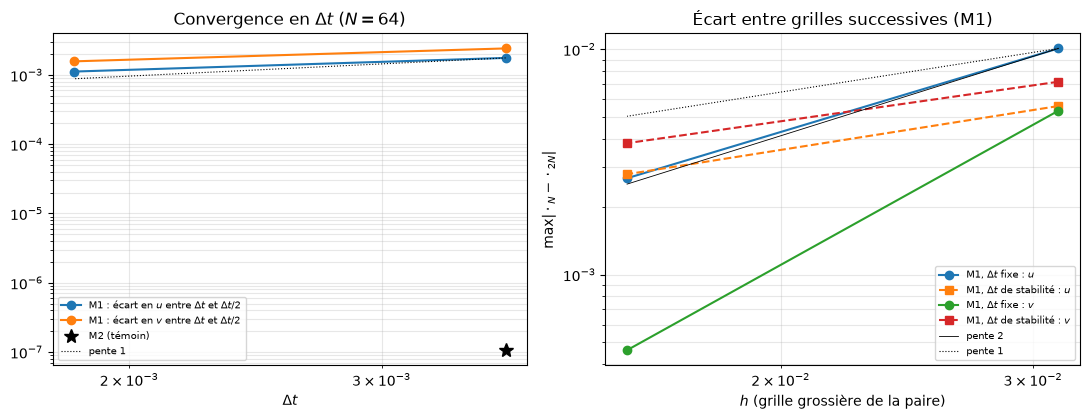

In [10]:
DT_FIX = runs[128]["dt"]                       # Δt de stabilité de N = 128, imposé à toutes les grilles
DT0_64 = runs[64]["dt"]
compute_missing([(n, CG_TOL, EPS, DT_FIX) for n in (32, 64)]
                + [(64, CG_TOL, EPS, DT0_64 / 2), (64, CG_TOL, EPS, DT0_64 / 4)])
compute_missing([(64, CG_TOL, EPS), (64, CG_TOL, EPS, DT0_64 / 2)], method="M2")


def profile_gap(ra, rb, n_a, n_b):
    # max|écart| sur les deux lignes médianes, aux nœuds communs (n_b = n_a ou 2 n_a)
    ua, va = centerlines(ra)
    ub, vb = centerlines(rb)
    step = n_b // n_a
    return np.abs(ua - ub[::step]).max(), np.abs(va - vb[::step]).max()


# (1) convergence en Δt à N = 64
dts = [DT0_64, DT0_64 / 2, DT0_64 / 4]
m1_dt = [runs[64], get_run(64, EPS, dt=dts[1]), get_run(64, EPS, dt=dts[2])]
gaps_dt = [profile_gap(m1_dt[k], m1_dt[k + 1], 64, 64) for k in range(2)]
m2_gap = profile_gap(get_run(64, EPS, method="M2"), get_run(64, EPS, method="M2", dt=dts[1]), 64, 64)
print("(1) Convergence en Δt, N = 64")
for k in range(2):
    print(f"   M1 : Δt {dts[k]:.3e} -> {dts[k + 1]:.3e} : max|Δu| = {gaps_dt[k][0]:.2e}, max|Δv| = {gaps_dt[k][1]:.2e}")
ratios = [gaps_dt[0][k] / gaps_dt[1][k] for k in (0, 1)]
print(f"   rapport des écarts successifs (2 si l'erreur est ∝ Δt) : u {ratios[0]:.2f}, v {ratios[1]:.2f}"
      f"   ⇒ ordre observé en Δt : u {np.log2(ratios[0]):.2f}, v {np.log2(ratios[1]):.2f}")
print(f"   M2 (témoin) : Δt {dts[0]:.3e} -> {dts[1]:.3e} : max|Δu| = {m2_gap[0]:.1e}, max|Δv| = {m2_gap[1]:.1e}")

# (2) étude de grille à Δt fixe
m1_fix = {32: get_run(32, EPS, dt=DT_FIX), 64: get_run(64, EPS, dt=DT_FIX), 128: runs[128]}
succ_fix = np.array([profile_gap(m1_fix[n], m1_fix[2 * n], n, 2 * n) for n in (32, 64)])
print(f"\n(2) Étude de grille à Δt fixe = {DT_FIX:.3e}")
for k, name in enumerate(("u", "v")):
    s_fix = np.log2(succ_fix[0, k] / succ_fix[1, k])
    s_stab = np.log2(diff_succ[0, k] / diff_succ[1, k])
    print(f"   {name} : écarts grilles successives {np.round(succ_fix[:, k], 5)}  pente {s_fix:.2f}"
          f"   (avec le Δt de stabilité : {np.round(diff_succ[:, k], 5)}, pente {s_stab:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ax = axes[0]
mid_dt = np.array([0.5 * (dts[k] + dts[k + 1]) for k in range(2)])
for k, name in enumerate(("u", "v")):
    ax.loglog(mid_dt, [g[k] for g in gaps_dt], "o-", label=f"M1 : écart en ${name}$ entre $\\Delta t$ et $\\Delta t/2$")
ax.loglog([0.5 * (dts[0] + dts[1])], [max(m2_gap)], "k*", ms=10, label="M2 (témoin)")
ax.loglog(mid_dt, gaps_dt[0][0] * mid_dt / mid_dt[0], "k:", lw=0.8, label="pente 1")
ax.set_xlabel(r"$\Delta t$"); ax.set_title("Convergence en $\\Delta t$ ($N = 64$)")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
ax = axes[1]
for k, name in enumerate(("u", "v")):
    ax.loglog(h_list[:-1], succ_fix[:, k], "o-", label=f"M1, $\\Delta t$ fixe : ${name}$")
    ax.loglog(h_list[:-1], diff_succ[:, k], "s--", label=f"M1, $\\Delta t$ de stabilité : ${name}$")
ax.loglog(h_list[:-1], succ_fix[0, 0] * (h_list[:-1] / h_list[0])**2, "k-", lw=0.6, label="pente 2")
ax.loglog(h_list[:-1], succ_fix[0, 0] * (h_list[:-1] / h_list[0])**1, "k:", lw=0.8, label="pente 1")
ax.set_xlabel("$h$ (grille grossière de la paire)"); ax.set_ylabel(r"$\max|\cdot_N - \cdot_{2N}|$")
ax.set_title("Écart entre grilles successives (M1)")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "A_M1_space_vs_dt.png", dpi=150)
plt.show()

**Lecture.**
- **(1) L'état stationnaire de M1 dépend de $\Delta t$** : à $N = 64$, diviser $\Delta t$ par 2 change les profils de $1.8\cdot10^{-3}$, puis de $1.1\cdot10^{-3}$ ;
  celui de M2 ne bouge pas ($10^{-7}$, l'erreur d'arrêt). C'est l'identité $D(u) = \Delta t\,(\Delta_h - D\tilde G)p$ de la projection du cours.
- Le rapport des écarts successifs vaut **1.55**, pas 2 : l'erreur en $\Delta t$ converge, mais à un ordre observé **≈ 0.65**, inférieur à 1. Le
  facteur $(\Delta_h - D\tilde G)p$ dépend lui-même de $\Delta t$ ; on ne sait pas l'expliquer plus avec ces mesures (trois $\Delta t$ seulement).
  Ordre de grandeur : à $N = 64$, la part $E_{\Delta t}$ au $\Delta t$ de stabilité vaut **au moins** $1.8\cdot10^{-3}$ (premier écart), et plutôt quelques
  $10^{-3}$, autant que l'écart entre les grilles $64$ et $128$ ($2.8\cdot10^{-3}$).
- **(2) À $\Delta t$ fixe, M1 est d'ordre 2 en espace** : pente **1.91** en $u$ (la pente en $v$, 3.5, repose sur des écarts de $5\cdot10^{-4}$, trop
  petits pour être fiables). La Neumann à fantômes a donc bien rendu M1 d'ordre 2 en espace.
- **D'où venait la pente ≈ 1 de 2.d** : avec le $\Delta t$ de stabilité, la part $E_{\Delta t}$ change d'une grille à l'autre ($\Delta t$ divisé par 2.56 puis
  par 4) et domine les écarts entre grilles. Ce n'est pas un ordre 1 en $h$.
- **Pour l'oral** : M1 a deux erreurs, l'une en espace (ordre 2, sous contrôle), l'autre due au **découplage de la projection du cours**
  (ordre < 1 en $\Delta t$). À nos grilles, c'est la seconde qui domine. M2 n'a pas la seconde.

### 2.f $K(t)$ et $P(t)$, et décroissance du résidu

**Ce qu'on fait.** Les deux diagnostics de l'énoncé, à chaque pas de temps, pour les trois grilles. À droite, le résidu
stationnaire $\|R\|$ (échelle log), avec $t_\text{ref}$ et le seuil d'arrêt $\varepsilon\|R(t_\text{ref})\|$ de chaque grille.

**Ce qu'on attend.** $K$ et $P$ montent avec la rampe du couvercle (temps caractéristique 1), puis tendent vers un
palier. $K$ devrait converger avec $N$ (grandeur intégrale, régulière) ; $P$ devrait **croître** avec $N$
(singularité des coins). Le résidu devrait décroître exponentiellement, avec la même pente sur les trois grilles
(le taux d'amortissement $\lambda$ est une propriété de l'écoulement).

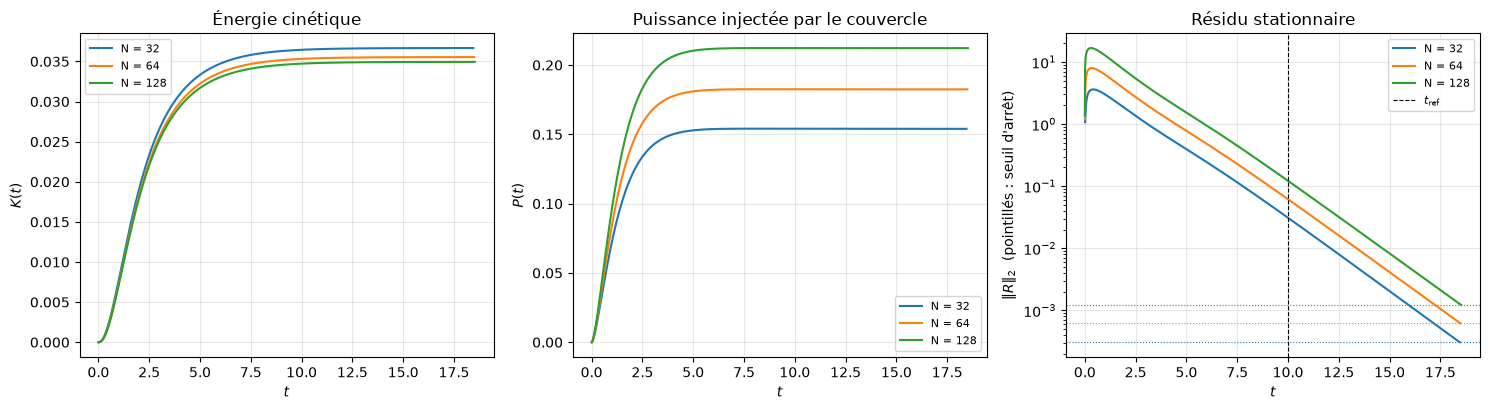

N =  32   arrêt à t = 18.45   λ = 0.547   K_final = 0.036669   P_final = 0.153988
N =  64   arrêt à t = 18.49   λ = 0.543   K_final = 0.035538   P_final = 0.182472
N = 128   arrêt à t = 18.52   λ = 0.541   K_final = 0.034941   P_final = 0.212199


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for n, r in runs.items():
    axes[0].plot(r["t"], r["K"], label=f"N = {n}")
    axes[1].plot(r["t"], r["P"], label=f"N = {n}")
    line, = axes[2].semilogy(r["t"], r["residual"], label=f"N = {n}")
    axes[2].axhline(EPS * r["residual_ref"], color=line.get_color(), ls=":", lw=0.8)
axes[2].axvline(T_REF, color="k", ls="--", lw=0.8, label=r"$t_\mathrm{ref}$")
axes[0].set_ylabel("$K(t)$"); axes[1].set_ylabel("$P(t)$")
axes[2].set_ylabel(r"$\|R\|_2$  (pointillés : seuil d'arrêt)")
for ax in axes:
    ax.set_xlabel("$t$"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
axes[0].set_title("Énergie cinétique"); axes[1].set_title("Puissance injectée par le couvercle")
axes[2].set_title("Résidu stationnaire")
fig.tight_layout()
fig.savefig(FIG / "A_M1_K_P.png", dpi=150)
plt.show()

# Taux d'amortissement λ : pente de ln||R|| après t_ref (régression écrite à la main, cf. observed_slopes)
for n, r in runs.items():
    after = r["t"] >= T_REF
    tt, lr = r["t"][after], np.log(r["residual"][after])
    lam = -np.sum((tt - tt.mean()) * (lr - lr.mean())) / np.sum((tt - tt.mean())**2)
    print(f"N = {n:3d}   arrêt à t = {r['t_final']:.2f}   λ = {lam:.3f}   "
          f"K_final = {r['K'][-1]:.6f}   P_final = {r['P'][-1]:.6f}")

**Lecture.**
- $K$ et $P$ suivent la rampe du couvercle puis atteignent un palier vers $t \approx 6$–$8$, sans dépassement : à $Re = 100$, le
  régime transitoire est un simple amortissement visqueux.
- **$K$ converge** : 0.03667, 0.03554, 0.03494 ; il décroît vers la valeur de M2 ($\approx 0.0344$, section 3), avec des accroissements
  divisés par ~2 (même lecture que les profils : la part $E_{\Delta t}$ domine).
- **$P$ ne converge pas** : 0.154, 0.182, 0.212 (voir 2.g).
- **Résidu** : décroissance exponentielle après le transitoire, avec **le même taux sur les trois grilles**, $\lambda \approx 0.54$ :
  propriété de l'écoulement. Les résidus L2 ne sont pas égaux (la somme porte sur plus de nœuds quand $N$ grandit), mais le
  critère étant un **rapport** à $\|R(t_\text{ref})\|$, les trois grilles s'arrêtent au même instant.

### 2.g $P$ stationnaire en fonction de $\ln N$

**Ce qu'on fait.** On trace $P_\text{final}$ contre $\ln N$ et on ajuste $P = a + c\ln N$ (régression sur 3 points).

**Ce qu'on attend** (PLAN.md §2, « Singularités aux coins du couvercle ») : aux deux coins, la vitesse de paroi saute
de $U_t$ à 0, $\partial_y u \sim 1/r$, donc $\int \nu\,\partial_y u\,dx$ diverge comme $\ln$ en continu. La grille coupe à $r \approx h$ :
$P \approx P_\text{régulier} + c\,\nu\ln N$. On attend donc **une droite, sans palier** : $P$ ne converge pas en maillage
et ne peut pas servir à choisir $N$. Le choix de $N$ se fait sur les profils (2.d, 2.e) et sur $K$.

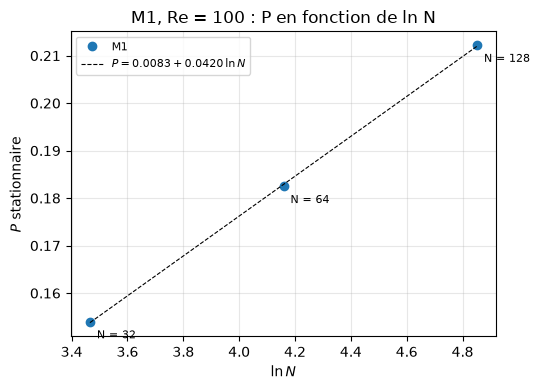

P_final : [0.153988 0.182472 0.212199]   accroissements : [0.028484 0.029727]
pente c = 0.04199   c / ν = 4.199
K_final : [0.036669 0.035538 0.034941]   accroissements : [-0.001131 -0.000597]


In [12]:
n_arr = np.array(GRIDS, dtype=float)
p_final = np.array([runs[n]["P"][-1] for n in GRIDS])
k_final = np.array([runs[n]["K"][-1] for n in GRIDS])
ln_n = np.log(n_arr)
c_fit = np.sum((ln_n - ln_n.mean()) * (p_final - p_final.mean())) / np.sum((ln_n - ln_n.mean())**2)
a_fit = p_final.mean() - c_fit * ln_n.mean()

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(ln_n, p_final, "o", label="M1")
ax.plot(ln_n, a_fit + c_fit * ln_n, "k--", lw=0.8, label=rf"$P = {a_fit:.4f} + {c_fit:.4f}\,\ln N$")
for n, lp, pp in zip(GRIDS, ln_n, p_final):
    ax.annotate(f"N = {n}", (lp, pp), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set_xlabel(r"$\ln N$"); ax.set_ylabel(r"$P$ stationnaire")
ax.set_title(f"M1, Re = {RE} : P en fonction de ln N")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A_M1_P_lnN.png", dpi=150)
plt.show()

print("P_final :", np.round(p_final, 6), "  accroissements :", np.round(np.diff(p_final), 6))
print(f"pente c = {c_fit:.5f}   c / ν = {c_fit / NU:.3f}")
print("K_final :", np.round(k_final, 6), "  accroissements :", np.round(np.diff(k_final), 6))

**Lecture.** $P$ augmente de **0.028 puis 0.030** à chaque doublement de $N$ : les trois points sont presque alignés en $\ln N$, sans palier,
comme attendu pour la singularité des coins ($P \approx a + c\ln N$, $c \approx 0.042 \approx 4.2\nu$). Les accroissements croissent légèrement
(+4 %) : la partie régulière de $P$ s'ajoute à la croissance logarithmique ; 3 points ne permettent pas de séparer les deux.
**Conséquence** : $P$ ne sert pas à choisir $N$ ; dans les Parties B et C, on comparera toujours les $P$ **à $N$ (et méthode) fixés**.

### 2.h Effet de la tolérance du gradient conjugué (workshop 15)

**Ce qu'on fait** (ADR 0003 §3) : on refait $N = 128$, la grille la plus exigeante, avec tol $= 10^{-10}$ au lieu de $10^{-8}$
(même $\varepsilon$), et on compare les profils.

**Ce qu'on attend.** Si l'écart entre les deux calculs est très petit devant l'écart à Ghia, une tolérance fixe de
$10^{-8}$ suffit pour toutes nos grilles. Le calcul coûte plus cher (plus d'itérations par pas).

In [13]:
compute_missing([(128, 1e-10, EPS)])
r8 = runs[128]
r10 = get_run(128, EPS, cg_tol=1e-10)
u8, v8 = centerlines(r8)
u10, v10 = centerlines(r10)
eu8, ev8 = ghia_errors(r8)
print(f"tol 1e-8  : it. GC moy = {r8['cg_iterations'].mean():6.1f}   t_final = {r8['t_final']:.2f}")
print(f"tol 1e-10 : it. GC moy = {r10['cg_iterations'].mean():6.1f}   t_final = {r10['t_final']:.2f}")
print(f"max|u(1e-8) - u(1e-10)| = {np.abs(u8 - u10).max():.2e}   (écart à Ghia : {eu8:.2e})")
print(f"max|v(1e-8) - v(1e-10)| = {np.abs(v8 - v10).max():.2e}   (écart à Ghia : {ev8:.2e})")
print(f"P : {r8['P'][-1]:.6f} (1e-8)  vs  {r10['P'][-1]:.6f} (1e-10)")

calculé : M1, N = 128, tol GC = 1e-10, ε = 1e-02
tol 1e-8  : it. GC moy =  161.0   t_final = 18.52
tol 1e-10 : it. GC moy =  328.9   t_final = 18.52
max|u(1e-8) - u(1e-10)| = 1.42e-10   (écart à Ghia : 6.43e-03)
max|v(1e-8) - v(1e-10)| = 2.86e-10   (écart à Ghia : 1.22e-02)
P : 0.212199 (1e-8)  vs  0.212199 (1e-10)


**Lecture.** Passer de tol $= 10^{-8}$ à $10^{-10}$ change les profils de $\sim 10^{-10}$, soit **sept ordres de grandeur sous** l'écart à Ghia, et ne
change pas $P$. La borne de l'ADR 0003 ($\sim 7\cdot10^{-5}$) était très pessimiste. **tol $= 10^{-8}$ suffit** pour toutes nos grilles ; la diminuer
doublerait le nombre d'itérations du gradient conjugué, pour rien.

### 2.i Récapitulatif M1 (sauvegardé dans `results/A_M1_summary.csv`)

Temps de calcul de référence : mesurés en 2.a pendant que 9 calculs tournaient en parallèle. Pour mémoire, le
portage Numba a été vérifié contre l'ancienne version numpy pure (`results/ref_numpy/`, ancien critère d'arrêt) :
mêmes champs à $2\cdot10^{-10}$ près, et 3 à 5 fois plus rapide (N = 32 : 0.6 s contre 2.9 s ; N = 64 : 5.2 s contre 21.5 s ;
N = 128 : 99 s contre 299 s).

In [14]:
summary = np.array([[n, runs[n]["dt"], runs[n]["n_steps"], runs[n]["t_final"], runs[n]["wall_time"],
                     runs[n]["cg_iterations"].mean(), *ghia_errors(runs[n]),
                     runs[n]["K"][-1], runs[n]["P"][-1]] for n in GRIDS])
np.savetxt(RES / "A_M1_summary.csv", summary, delimiter=",", fmt="%.6e",
           header=f"critere residu eps = {EPS:.0e} (t_ref = {T_REF}), tol GC {CG_TOL:.0e}\n"
                  "N,dt,n_steps,t_final,wall_time_s,cg_iter_mean,err_ghia_u,err_ghia_v,K_final,P_final")
for row in summary:
    print(f"N = {int(row[0]):3d}   calcul = {row[4]:7.1f} s   écart Ghia (u, v) = ({row[6]:.4f}, {row[7]:.4f})"
          f"   K = {row[8]:.5f}   P = {row[9]:.5f}")

N =  32   calcul =     5.2 s   écart Ghia (u, v) = (0.0102, 0.0206)   K = 0.03667   P = 0.15399
N =  64   calcul =    21.4 s   écart Ghia (u, v) = (0.0090, 0.0158)   K = 0.03554   P = 0.18247
N = 128   calcul =   167.9 s   écart Ghia (u, v) = (0.0064, 0.0122)   K = 0.03494   P = 0.21220


**Bilan de l'étape 2 (M1, $Re = 100$).** Avec la Neumann à fantômes, M1 est d'ordre 2 en espace (vérifié à $\Delta t$ fixe) ; son erreur à nos
grilles est dominée par l'**erreur de projection**, qui dépend de $\Delta t$ (ordre ≈ 0.65 en $\Delta t$), propre à la méthode du cours.
Écart à Ghia à $N = 128$ : $6\cdot10^{-3}$ en $u$, $1.2\cdot10^{-2}$ en $v$ (environ 3 % et 5 % des extrema). $K$ converge, $P$ croît en $\ln N$ (coins).
Réglages validés : tol $= 10^{-8}$ ; critère d'arrêt sur le résidu, $\varepsilon = 10^{-2}$ à partir de $t_\text{ref} = 10$. Grille retenue : $N = 128$
(au-delà, le coût est multiplié par ~25 à chaque doublement, et c'est $\Delta t$, pas $h$, qui limite la précision de M1).

## 3. M2 (fonction de courant / vorticité) et validation croisée M1 / M2

### 3.a Calculs M2

**Ce qu'on fait.** M2 (`cavity/psi_omega.py`, cours §7.3.4) sur la **même grille** et avec les **mêmes briques** que M1
(`cavity/common.py`) : Euler explicite, advection centrée, diffusion centrée, gradient conjugué (ici en Dirichlet pour
$\Delta\psi = -\omega$, tol $= 10^{-8}$, départ à chaud), même $\Delta t$, même critère d'arrêt sur le résidu ($\varepsilon$ retenu en 2.b) et
mêmes diagnostics $K$, $P$. Vorticité de paroi par la formule de Thom (Taylor sur $\psi$, cf. `docs/pseudocode.md`).
$N = 32, 64, 128$, en parallèle.

**Ce qu'on attend.** Un écoulement stationnaire proche de celui de M1 et de Ghia. M2 n'a **pas de pression**, donc pas de
condition de Neumann : si la Neumann d'ordre 1 de M1 limite sa précision (ADR 0002), M2 devrait être plus précis et
converger plus vite. Coût par pas comparable (un Poisson par pas dans les deux cas).

In [15]:
compute_missing([(n, CG_TOL, EPS) for n in GRIDS], method="M2")
runs2 = {n: get_run(n, EPS, method="M2") for n in GRIDS}

print(f"{'N':>4} {'dt':>9} {'pas':>6} {'t_final':>7} {'M2 (s)':>8} {'M1 (s)':>8} {'it. GC M2':>9} {'it. GC M1':>9} {'arrêt':>8}")
for n in GRIDS:
    r2, r1 = runs2[n], runs[n]
    stop = "critère" if r2["converged"] else "t_max !"
    print(f"{n:4d} {r2['dt']:9.3e} {r2['n_steps']:6d} {r2['t_final']:7.2f} {r2['wall_time']:8.1f} "
          f"{r1['wall_time']:8.1f} {r2['cg_iterations'].mean():9.1f} {r1['cg_iterations'].mean():9.1f} {stop:>8}")
print("(temps mesurés avec plusieurs calculs en parallèle)")

calculé : M2, N = 32, tol GC = 1e-08, ε = 1e-02
calculé : M2, N = 128, tol GC = 1e-08, ε = 1e-02
   N        dt    pas t_final   M2 (s)   M1 (s) it. GC M2 it. GC M1    arrêt
  32 1.250e-02   1491   18.64      0.8      5.2      59.1      80.1  critère
  64 4.883e-03   3803   18.57      5.0     21.4     113.0     127.7  critère
 128 1.221e-03  15201   18.56    106.2    167.9     205.5     161.0  critère
(temps mesurés avec plusieurs calculs en parallèle)


**Lecture.** M2 devient stationnaire sur les trois grilles, au même instant que M1 ($t \approx 18.5$ : même critère, même taux
d'amortissement, c'est bien le même écoulement). Il est moins cher que M1 (un Poisson par pas dans les deux cas, mais un seul
champ transporté, $\omega$, au lieu de $u$ et $v$, pas de divergence ni de gradient de pression, et un Poisson Dirichlet sur moins
d'inconnues que la Neumann à fantômes).

### 3.a bis Décroissance du résidu : M1 et M2

**Ce qu'on fait.** Le résidu stationnaire $\|R\|_2 = \|(u^{n+1}-u^n)/\Delta t\|$ (critère d'arrêt commun, ADR 0003 §2) en fonction de $t$,
un panneau par solveur, pour les trois grilles, avec $t_\text{ref}$ et le seuil d'arrêt $\varepsilon\|R(t_\text{ref})\|$ de chaque grille.
Le taux d'amortissement $\lambda$ est la pente de $\ln\|R\|$ après $t_\text{ref}$ (régression écrite à la main, comme en 2.f).

**Ce qu'on attend.** Pour les deux solveurs, une décroissance exponentielle après le transitoire, avec le **même** $\lambda$ :
c'est une propriété de l'écoulement (mode le plus lent de l'approche du stationnaire), pas de la méthode.

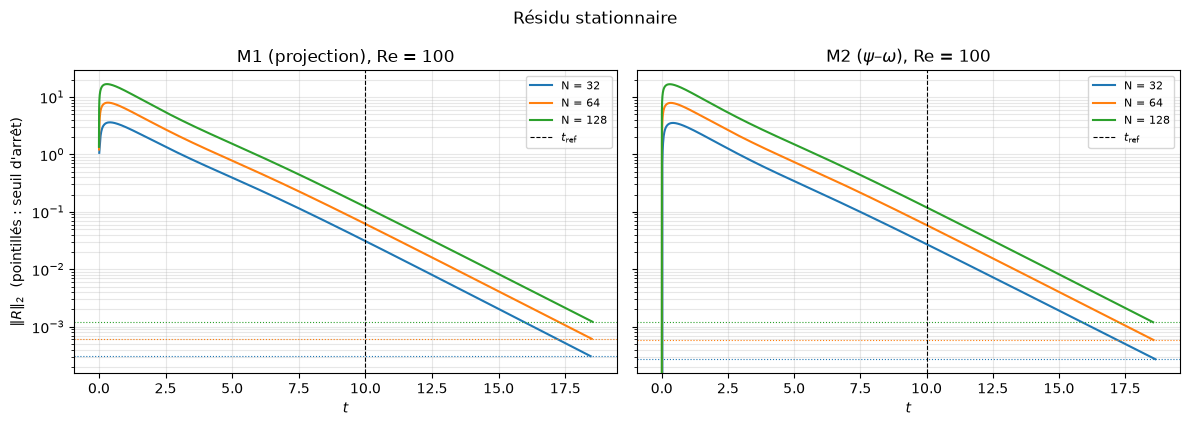

N =  32   λ M1 = 0.547   λ M2 = 0.535   arrêt M1 t = 18.45, M2 t = 18.64
N =  64   λ M1 = 0.543   λ M2 = 0.538   arrêt M1 t = 18.49, M2 t = 18.57
N = 128   λ M1 = 0.541   λ M2 = 0.539   arrêt M1 t = 18.52, M2 t = 18.56


In [16]:
def damping_rate(r):
    # λ = -pente de ln||R|| pour t >= t_ref (moindres carrés écrits à la main)
    after = r["t"] >= T_REF
    tt, lr = r["t"][after], np.log(r["residual"][after])
    return -np.sum((tt - tt.mean()) * (lr - lr.mean())) / np.sum((tt - tt.mean())**2)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, (label, rr) in zip(axes, (("M1 (projection)", runs), (r"M2 ($\psi$–$\omega$)", runs2))):
    for n, r in rr.items():
        line, = ax.semilogy(r["t"], r["residual"], label=f"N = {n}")
        ax.axhline(EPS * r["residual_ref"], color=line.get_color(), ls=":", lw=0.8)
    ax.axvline(T_REF, color="k", ls="--", lw=0.8, label=r"$t_\mathrm{ref}$")
    ax.set_xlabel("$t$"); ax.set_title(f"{label}, Re = {RE}")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\|R\|_2$  (pointillés : seuil d'arrêt)")
fig.suptitle("Résidu stationnaire")
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_residuals.png", dpi=150)
plt.show()

for n in GRIDS:
    print(f"N = {n:3d}   λ M1 = {damping_rate(runs[n]):.3f}   λ M2 = {damping_rate(runs2[n]):.3f}   "
          f"arrêt M1 t = {runs[n]['t_final']:.2f}, M2 t = {runs2[n]['t_final']:.2f}")

**Lecture.**
- **Mêmes courbes pour M1 et M2** : montée pendant la rampe du couvercle ($t \lesssim 0.5$), puis décroissance exponentielle
  jusqu'à l'arrêt. Le taux d'amortissement est **le même pour les deux solveurs et les trois grilles** : $\lambda \approx 0.54$
  (M1 : 0.547, 0.543, 0.541 ; M2 : 0.535, 0.538, 0.539, les deux séries se rapprochant quand $N$ augmente). C'est une propriété de
  l'écoulement, pas de la méthode : les deux solveurs s'arrêtent au même instant ($t \approx 18.5$–$18.6$).
- **Niveau de $\|R\|$ proportionnel à $N$** (×2 par doublement) pour les deux solveurs : norme L2 sur $(N-1)^2$ nœuds non pondérée
  par $h^2$. Sans effet sur l'arrêt, le critère étant un **rapport** à $\|R(t_\text{ref})\|$.
- **Seule différence, au premier pas** : $\|R\| = 0$ pour M2. La vorticité de paroi (Thom) n'est calculée qu'à la fin du pas
  (`psi_omega_step`, étape 4) : au premier pas elle vaut encore 0, donc $\omega$, $\psi$ et les vitesses intérieures restent nulles.
  M1 voit le couvercle dès le premier pas (vitesse de paroi dans l'advection et la diffusion). Ce retard d'un pas est sans effet visible
  dès $t \approx 0.1$.

### 3.b M1, M2 et Ghia sur la même figure

**Ce qu'on fait.** Profils $u(0.5, y)$ et $v(x, 0.5)$ à $N = 128$ (grille retenue) pour M1 et M2, avec les points de Ghia ;
en dessous, l'écart M1 − M2 le long des deux lignes médianes, pour les trois grilles.

**Ce qu'on attend.** Les deux méthodes et Ghia superposés à l'échelle du tracé. L'écart M1 − M2 doit diminuer quand $N$
augmente (les deux méthodes discrétisent le même problème continu) ; sa forme indique où les méthodes diffèrent.

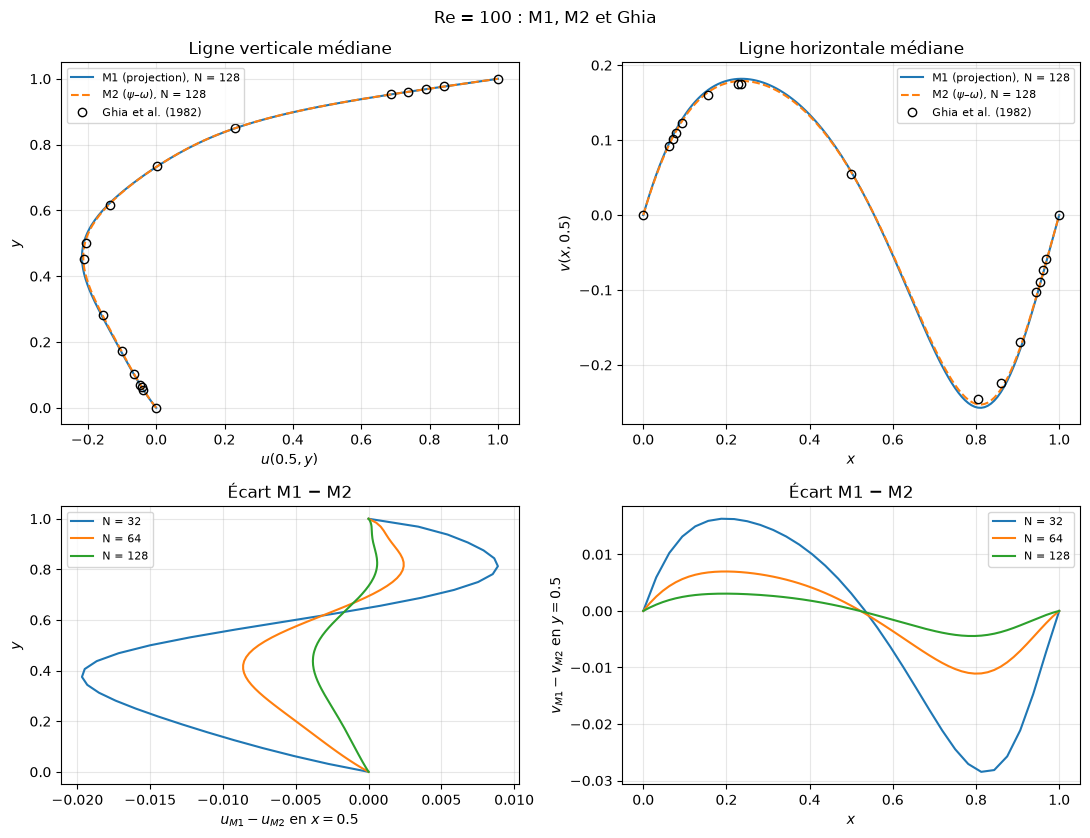

N =  32   max|M1 - M2| : u 0.0197, v 0.0284   |   écart à Ghia  M1 : u 0.0102, v 0.0206   M2 : u 0.0089, v 0.0086
N =  64   max|M1 - M2| : u 0.0086, v 0.0111   |   écart à Ghia  M1 : u 0.0090, v 0.0158   M2 : u 0.0026, v 0.0059
N = 128   max|M1 - M2| : u 0.0038, v 0.0044   |   écart à Ghia  M1 : u 0.0064, v 0.0122   M2 : u 0.0042, v 0.0084
pente de max|M1 - M2| en u : locales [1.19 1.17]  (globale 1.18)
pente de max|M1 - M2| en v : locales [1.36 1.32]  (globale 1.34)


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), gridspec_kw={"height_ratios": [1.3, 1]})
u1, v1 = centerlines(runs[128])
u2, v2 = centerlines(runs2[128])
x128, y128 = runs[128]["x"], runs[128]["y"]
axes[0, 0].plot(u1, y128, label="M1 (projection), N = 128")
axes[0, 0].plot(u2, y128, "--", label=r"M2 ($\psi$–$\omega$), N = 128")
axes[0, 0].plot(u_ghia, y_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[0, 1].plot(x128, v1, label="M1 (projection), N = 128")
axes[0, 1].plot(x128, v2, "--", label=r"M2 ($\psi$–$\omega$), N = 128")
axes[0, 1].plot(x_ghia, v_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[0, 0].set_xlabel("$u(0.5, y)$"); axes[0, 0].set_ylabel("$y$")
axes[0, 1].set_xlabel("$x$"); axes[0, 1].set_ylabel("$v(x, 0.5)$")
axes[0, 0].set_title("Ligne verticale médiane"); axes[0, 1].set_title("Ligne horizontale médiane")

for n in GRIDS:
    a1, b1 = centerlines(runs[n])
    a2, b2 = centerlines(runs2[n])
    axes[1, 0].plot(a1 - a2, runs[n]["y"], label=f"N = {n}")
    axes[1, 1].plot(runs[n]["x"], b1 - b2, label=f"N = {n}")
axes[1, 0].set_xlabel(r"$u_{M1} - u_{M2}$ en $x = 0.5$"); axes[1, 0].set_ylabel("$y$")
axes[1, 1].set_xlabel("$x$"); axes[1, 1].set_ylabel(r"$v_{M1} - v_{M2}$ en $y = 0.5$")
axes[1, 0].set_title("Écart M1 − M2"); axes[1, 1].set_title("Écart M1 − M2")
for ax in axes.ravel():
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"Re = {RE} : M1, M2 et Ghia")
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_Ghia.png", dpi=150)
plt.show()

diff_m1m2 = np.array([[np.abs(centerlines(runs[n])[k] - centerlines(runs2[n])[k]).max() for k in (0, 1)]
                      for n in GRIDS])
for n, (du, dv) in zip(GRIDS, diff_m1m2):
    eu1, ev1 = ghia_errors(runs[n])
    eu2, ev2 = ghia_errors(runs2[n])
    print(f"N = {n:3d}   max|M1 - M2| : u {du:.4f}, v {dv:.4f}   |   écart à Ghia  M1 : u {eu1:.4f}, v {ev1:.4f}"
          f"   M2 : u {eu2:.4f}, v {ev2:.4f}")
for k, name in enumerate(("u", "v")):
    local, glob = observed_slopes(GRIDS, diff_m1m2[:, k])
    print(f"pente de max|M1 - M2| en {name} : locales {np.round(local, 2)}  (globale {glob:.2f})")

**Lecture.**
- À $N = 128$, M1, M2 et Ghia se superposent à l'échelle du tracé sur $u$ ; sur $v$, M1 et M2 creusent tous deux le minimum plus que
  Ghia, M1 un peu plus que M2.
- **L'écart M1 − M2 diminue avec $N$** (0.020 → 0.009 → 0.004 en $u$ ; 0.028 → 0.011 → 0.004 en $v$) : les deux méthodes convergent vers
  **la même solution**. Pente ≈ 1.2–1.3 : c'est la part $E_{\Delta t}$ de M1 (2.e), qui diminue avec le $\Delta t$ de stabilité, qui fixe ce rythme.
- La forme de l'écart est la même sur les trois grilles (régulière, étalée dans le tourbillon) : ce n'est pas une erreur localisée aux
  coins.

### 3.c Convergence en maillage de M2, comparée à M1 — lecture des pentes

**Ce qu'on fait.** Les deux mêmes courbes qu'en 2.d (écart à Ghia ; écart entre grilles successives), pour M2, tracées avec
celles de M1. Lecture prévue par PLAN.md (étape 2) et l'ADR 0002 :
- pente faible pour **M1 et M2** ⇒ suspect = **singularités des coins** (elles touchent les deux méthodes) ;
- pente faible pour **M1 seulement** (≈ 1–1.5 pour M1, ≈ 2 pour M2) ⇒ suspect = **Neumann d'ordre 1 sur $p$** (propre à M1).

Historique (ADR 0002 §5–7) : cette lecture, faite d'abord avec la première version de M1 (Neumann d'ordre 1, « M1 ordre 1 »),
désignait la Neumann ; on est passé aux nœuds fantômes. Le tableau ci-dessous compare les trois variantes, avec le $\Delta t$ de
stabilité et, pour M1 à fantômes, à $\Delta t$ fixe (2.e).

**Ce qu'on attend.** M2 ≈ 2 ; M1 ordre 1 en dessous ; M1 à fantômes ≈ 2 à $\Delta t$ fixe, mais une pente plus faible avec le $\Delta t$ de
stabilité, à cause de la part $E_{\Delta t}$ (2.e).

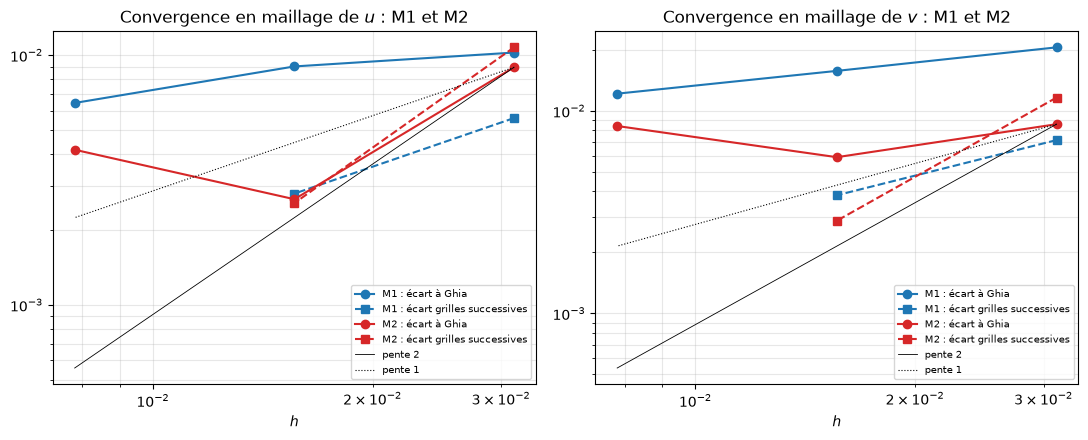

calculé : M1neu1, N = 32, tol GC = 1e-08, ε = 1e-02
calculé : M1neu1, N = 64, tol GC = 1e-08, ε = 1e-02
calculé : M1neu1, N = 128, tol GC = 1e-08, ε = 1e-02
                    variante |     écarts succ. u pente u |     écarts succ. v pente v
    M1 ordre 1, Δt stabilité |  [0.02891 0.01122]    1.37 |  [0.04111 0.0154 ]    1.42
   M1 fantômes, Δt stabilité |  [0.0056  0.00279]    1.00 |  [0.00717 0.00383]    0.91
        M1 fantômes, Δt fixe |  [0.01008 0.00268]    1.91 |  [0.00533 0.00046]    3.53
            M2, Δt stabilité |  [0.01074 0.00255]    2.07 |  [0.01163 0.00287]    2.02

Écart à Ghia (u, v) :
   N =  32   M1 ordre 1 [0.0421 0.057 ]   M1 fantômes [0.0102 0.0206]   M2 [0.0089 0.0086]
   N =  64   M1 ordre 1 [0.0141 0.0156]   M1 fantômes [0.009  0.0158]   M2 [0.0026 0.0059]
   N = 128   M1 ordre 1 [0.0041 0.0035]   M1 fantômes [0.0064 0.0122]   M2 [0.0042 0.0084]


In [18]:
err_ghia2 = np.array([ghia_errors(runs2[n]) for n in GRIDS])
diff_succ2 = []
for n in GRIDS[:-1]:
    u_c, v_c = centerlines(runs2[n])
    u_f, v_f = centerlines(runs2[2 * n])
    diff_succ2.append((np.abs(u_c - u_f[::2]).max(), np.abs(v_c - v_f[::2]).max()))
diff_succ2 = np.array(diff_succ2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for k, name in enumerate(("u", "v")):
    ax = axes[k]
    ax.loglog(h_list, err_ghia[:, k], "o-", color="C0", label=f"M1 : écart à Ghia")
    ax.loglog(h_list[:-1], diff_succ[:, k], "s--", color="C0", label=f"M1 : écart grilles successives")
    ax.loglog(h_list, err_ghia2[:, k], "o-", color="C3", label=f"M2 : écart à Ghia")
    ax.loglog(h_list[:-1], diff_succ2[:, k], "s--", color="C3", label=f"M2 : écart grilles successives")
    ref = err_ghia2[0, k]
    ax.loglog(h_list, ref * (h_list / h_list[0])**2, "k-", lw=0.6, label="pente 2")
    ax.loglog(h_list, ref * (h_list / h_list[0])**1, "k:", lw=0.8, label="pente 1")
    ax.set_xlabel("$h$"); ax.set_title(f"Convergence en maillage de ${name}$ : M1 et M2")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_grid_convergence.png", dpi=150)
plt.show()

# Première version de M1 (Neumann d'ordre 1), calculée avec le même ε (relue, ou recalculée si absente)
compute_missing([(n, CG_TOL, EPS) for n in GRIDS], method="M1neu1")
runs1n = {n: get_run(n, EPS, method="M1neu1") for n in GRIDS}
succ1n = np.array([profile_gap(runs1n[n], runs1n[2 * n], n, 2 * n) for n in GRIDS[:-1]])

variants = (("M1 ordre 1, Δt stabilité", succ1n), ("M1 fantômes, Δt stabilité", diff_succ),
            ("M1 fantômes, Δt fixe", succ_fix), ("M2, Δt stabilité", diff_succ2))
print(f"{'variante':>28} | {'écarts succ. u':>18} {'pente u':>7} | {'écarts succ. v':>18} {'pente v':>7}")
for label, s in variants:
    print(f"{label:>28} | {str(np.round(s[:, 0], 5)):>18} {np.log2(s[0, 0] / s[1, 0]):7.2f} | "
          f"{str(np.round(s[:, 1], 5)):>18} {np.log2(s[0, 1] / s[1, 1]):7.2f}")
print("\nÉcart à Ghia (u, v) :")
for n in GRIDS:
    print(f"   N = {n:3d}   M1 ordre 1 {np.round(ghia_errors(runs1n[n]), 4)}   M1 fantômes {np.round(ghia_errors(runs[n]), 4)}"
          f"   M2 {np.round(ghia_errors(runs2[n]), 4)}")

**Lecture.**
- **M2 ≈ 2.0** sur l'écart entre grilles ($u$ : 2.07, $v$ : 2.02), malgré les coins et malgré Thom (d'ordre 1 localement, mais l'ordre 2
  global est préservé, comme l'annonce Erturk et al.) ⇒ **les coins ne limitent pas l'ordre sur les profils**.
- **Les trois versions de M1** :
  - *ordre 1* (Neumann $p_0 = p_1$) : pente ≈ 1.4, erreurs les plus grandes (0.029 puis 0.011 en $u$) ;
  - *fantômes, $\Delta t$ de stabilité* : erreurs ~5 fois plus petites, mais pente ≈ 1 (part $E_{\Delta t}$, 2.e) ;
  - *fantômes, $\Delta t$ fixe* : **pente ≈ 1.9** : M1 est d'ordre 2 en espace.
- **La lecture du PLAN a donc fonctionné en deux temps** : (1) « pente faible pour M1 seul » a désigné la Neumann d'ordre 1, que
  les fantômes ont corrigée en espace ; (2) il restait une seconde erreur propre à M1, l'erreur de projection en $\Delta t$, que la
  grille de lecture ne prévoyait pas et qu'a révélée la comparaison avec M2 (ADR 0002 §7).
- **Écart à Ghia de M2** : il **ne diminue plus** entre $N = 64$ et $128$ (0.0026 → 0.0042 en $u$, 0.0059 → 0.0084 en $v$), alors que M2
  converge à l'ordre 2 (son $N = 128$ est à $\sim 10^{-3}$ de sa limite). C'est le palier annoncé par le PLAN : l'écart à Ghia mesure alors surtout
  **l'erreur de Ghia** (129×129, ordre 2), de l'ordre de $4$–$8\cdot10^{-3}$, pire sur le minimum de $v$ (M2 le donne ~3 % plus creusé).
- **Attention à une lecture trompeuse** : à $N = 128$, M1 *ordre 1* est plus proche de Ghia (0.004 / 0.004) que M1 *fantômes*
  (0.006 / 0.012). Ce n'est pas qu'il est plus juste : il est plus loin de M2 (0.006 contre 0.004) et sa pente est moins bonne ;
  il traverse les valeurs de Ghia en convergeant. On juge donc sur l'écart entre grilles et sur l'écart à M2, pas sur Ghia seul.

### 3.d $K$ et $P$ : M1 et M2

**Ce qu'on fait.** Valeurs stationnaires de $K$ et $P$ des deux méthodes sur les trois grilles, et $P$ en fonction de $\ln N$.

**Ce qu'on attend.** $K$ des deux méthodes vers une même limite. $P$ croissant en $\ln N$ pour les deux (singularité des coins,
propriété du problème et non de la méthode) ; les pentes $c$ peuvent différer un peu (les deux méthodes ne traitent pas
le voisinage du coin de la même façon : vitesse tirée de $\psi$ pour M2).

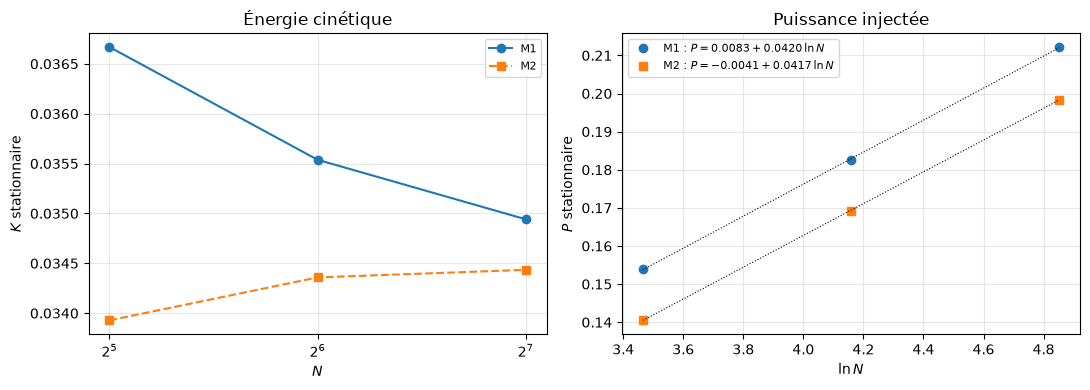

K M1 : [0.036669 0.035538 0.034941]  accroissements [-0.001131 -0.000597]
K M2 : [0.033927 0.034358 0.034434]  accroissements [4.31e-04 7.60e-05]
P M1 : [0.153988 0.182472 0.212199]  accroissements [0.028484 0.029727]
P M2 : [0.140579 0.169197 0.198399]  accroissements [0.028617 0.029203]
pentes c : M1 0.04199 (4.20 ν),  M2 0.04171 (4.17 ν)


In [19]:
k1 = np.array([runs[n]["K"][-1] for n in GRIDS]);  k2 = np.array([runs2[n]["K"][-1] for n in GRIDS])
p1 = np.array([runs[n]["P"][-1] for n in GRIDS]);  p2 = np.array([runs2[n]["P"][-1] for n in GRIDS])


def fit_ln(values):
    # P = a + c ln N, régression écrite à la main (comme en 2.g)
    c = np.sum((ln_n - ln_n.mean()) * (values - values.mean())) / np.sum((ln_n - ln_n.mean())**2)
    return values.mean() - c * ln_n.mean(), c


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(GRIDS, k1, "o-", label="M1"); axes[0].plot(GRIDS, k2, "s--", label="M2")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("$N$"); axes[0].set_ylabel("$K$ stationnaire")
axes[0].set_title("Énergie cinétique")
for vals, mk, lab in ((p1, "o", "M1"), (p2, "s", "M2")):
    a, c = fit_ln(vals)
    axes[1].plot(ln_n, vals, mk, label=f"{lab} : $P = {a:.4f} + {c:.4f}\\,\\ln N$")
    axes[1].plot(ln_n, a + c * ln_n, "k:", lw=0.8)
axes[1].set_xlabel(r"$\ln N$"); axes[1].set_ylabel("$P$ stationnaire"); axes[1].set_title("Puissance injectée")
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_K_P.png", dpi=150)
plt.show()

for name, a_, b_ in (("K", k1, k2), ("P", p1, p2)):
    print(f"{name} M1 : {np.round(a_, 6)}  accroissements {np.round(np.diff(a_), 6)}")
    print(f"{name} M2 : {np.round(b_, 6)}  accroissements {np.round(np.diff(b_), 6)}")
print(f"pentes c : M1 {fit_ln(p1)[1]:.5f} ({fit_ln(p1)[1] / NU:.2f} ν),  M2 {fit_ln(p2)[1]:.5f} ({fit_ln(p2)[1] / NU:.2f} ν)")

**Lecture.**
- **$K$** : M2 converge très vite (accroissements $4.3\cdot10^{-4}$ puis $7.6\cdot10^{-5}$, ordre ≈ 2.5) vers $K \approx 0.0344$–$0.0345$ ; M1 (fantômes)
  s'en approche par au-dessus (0.0367, 0.0355, 0.0349), plus lentement. Même lecture que sur les profils.
- **$P$** : les deux méthodes croissent en $\ln N$, avec des pentes presque égales ($c \approx 4.2\nu$ pour M1 comme pour M2) et des
  accroissements presque constants (≈ 0.029 par doublement). La croissance en $\ln N$ est une propriété du problème (singularité
  des coins), pas d'une méthode. Les valeurs de $P$ diffèrent de ~0.014 à $N$ fixé : on ne comparera les $P$ qu'à $N$ **et** méthode
  fixés.

### 3.e Récapitulatif M1 / M2 (sauvegardé dans `results/A_M1_M2_summary.csv`)

In [20]:
rows = []
for n in GRIDS:
    for tag, rr in (("M1", runs[n]), ("M2", runs2[n])):
        rows.append([n, 1 if tag == "M1" else 2, rr["wall_time"], rr["cg_iterations"].mean(),
                     *ghia_errors(rr), rr["K"][-1], rr["P"][-1]])
np.savetxt(RES / "A_M1_M2_summary.csv", np.array(rows), delimiter=",", fmt="%.6e",
           header=f"Re = {RE}, critere residu eps = {EPS:.0e} (t_ref = {T_REF}), tol GC {CG_TOL:.0e}\n"
                  "N,methode(1=M1 projection, 2=M2 psi-omega),wall_time_s,cg_iter_mean,err_ghia_u,err_ghia_v,K_final,P_final")
for row in rows:
    print(f"N = {int(row[0]):3d}  M{int(row[1])}   calcul = {row[2]:6.1f} s   écart Ghia (u, v) = ({row[4]:.4f}, {row[5]:.4f})"
          f"   K = {row[6]:.5f}   P = {row[7]:.5f}")

N =  32  M1   calcul =    5.2 s   écart Ghia (u, v) = (0.0102, 0.0206)   K = 0.03667   P = 0.15399
N =  32  M2   calcul =    0.8 s   écart Ghia (u, v) = (0.0089, 0.0086)   K = 0.03393   P = 0.14058
N =  64  M1   calcul =   21.4 s   écart Ghia (u, v) = (0.0090, 0.0158)   K = 0.03554   P = 0.18247
N =  64  M2   calcul =    5.0 s   écart Ghia (u, v) = (0.0026, 0.0059)   K = 0.03436   P = 0.16920
N = 128  M1   calcul =  167.9 s   écart Ghia (u, v) = (0.0064, 0.0122)   K = 0.03494   P = 0.21220
N = 128  M2   calcul =  106.2 s   écart Ghia (u, v) = (0.0042, 0.0084)   K = 0.03443   P = 0.19840


**Bilan des étapes 2 et 3 (Partie A).** M2, avec les mêmes briques que M1, converge à l'ordre 2 et sert de référence indépendante.
M1 (Neumann à fantômes) est d'ordre 2 en espace mais garde une erreur de projection qui dépend de $\Delta t$, propre à la méthode du
cours et dominante à nos grilles ; M1 et M2 convergent vers la même solution. L'écart de M2 à Ghia plafonne vers $4$–$8\cdot10^{-3}$,
vraisemblablement l'erreur propre de Ghia. $P$ croît en $\ln N$ pour les deux méthodes. Grille retenue : $N = 128$.